# Lab 2: Autoregressive models

Implement an autoregressive model (MADE) of discrete data and compare it with a model that assumes independence.

$$p(\mathbf{x}) = \prod_{i=1}^{D} p(x_i \mid x_1, \dots, x_{i-1})$$

## How to work

- You implement four functions in `lab02/tasks.py`. Their docstrings say what they get and what they must return. Everything else is up to you: model, training, helper functions.
- Inputs and returned values of your functions are **torch tensors**; work in torch (numpy is used only inside the plotting helpers).
- The notebook calls your functions and plots what they return. After saving `tasks.py`, rerun the cells - the script is reloaded automatically.
- There are no automatic checks. Look at the plots.
- Training takes a while. Use a GPU if you have one (e.g. Google Colab).

## Evaluation

As in Lab 1: negative log-likelihood (NLL) on test data, lower is better.

- 1D and 2D data: nats per example. A uniform distribution over $d$ values gives $\log d$ (3.0 for $d = 20$) and over $d \times d$ values $2 \log d$ (6.4 for $d = 25$, 10.6 for $d = 200$).
- Images: bits per pixel. Guessing every binary pixel with probability $\tfrac{1}{2}$ gives 1 bit per pixel.

In [1]:
# Make the course repository importable (no installation needed): its root holds the helper folder `udl/`
# and the lab folders such as `lab02/`. Locally the root is found above this notebook. On Colab the repository is cloned.
import subprocess
import sys
from pathlib import Path

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "udl").is_dir()), None)
if root is None:  # not inside the repository, e.g. Colab
    REPO = "https://gitlab.example.com/CHANGE-ME/udl26.git"  # TODO: your repo URL
    root = Path("udl26").resolve()
    if not root.exists():
        subprocess.run(["git", "clone", "-q", REPO, str(root)], check=True)
sys.path.insert(0, str(root))

In [2]:
# Reload the scripts automatically after you edit and save them
%load_ext autoreload
%autoreload 2

In [3]:
# Reload the scripts automatically after you edit and save them
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
import torch
import matplotlib.pyplot as plt

# provided helpers
from udl.lab02 import (load_categorical_1d, plot_categorical_fit, sample_gaussian_2d, load_2d, load_shapes, load_binary_mnist, count_table, plot_table, plot_2d_result,
                       plot_curves, show_images, report)

# your code (script in the folder `lab02/`)
from lab02.tasks import categorical_1d, independent_2d, made_2d, made_images

# A. One variable

A single discrete variable $x \in \{0, \dots, d-1\}$ with $d = 20$ values. We have **2 000 training and 5 000 test examples**. The plot shows the histogram of the training data: the relative frequency of every value.

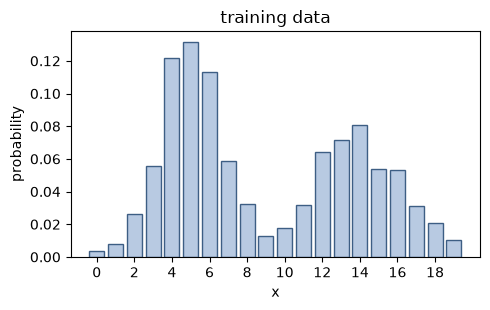

In [5]:
x_train, x_test, d_1d = load_categorical_1d()

fig, ax = plt.subplots(figsize=(5, 3.2))
plot_categorical_fit(ax, x_train, d_1d, title="training data")
plt.tight_layout()
plt.show()

## A1. Categorical distribution trained by gradient descent

The data have two bumps. Learning their distribution by counting is easy: the probability of a value is its relative frequency. Here you get the same distribution in a different way, by **training its parameters with gradient descent**. All models in this course are trained like this, so we practise on the simplest case.

**Model.** Every value $k$ has a probability $\theta_k$, with $\theta_k \ge 0$ and $\sum_k \theta_k = 1$, so $p(x = k) = \theta_k$.

**Parameters.** The constraints on $\theta$ are awkward for gradient descent. Instead, learn $d$ unconstrained numbers $\phi_0, \dots, \phi_{d-1}$ (the *logits*) and define

$$\theta_k = \frac{\exp(\phi_k)}{\sum_{c=0}^{d-1} \exp(\phi_c)}$$

which are non-negative and sum to one for any $\boldsymbol\phi$.

**Loss.** The negative log-likelihood of the training examples $x_1, \dots, x_N$:

$$L(\boldsymbol\phi) = -\frac{1}{N}\sum_{i=1}^{N} \log p(x_i) = -\frac{1}{N}\sum_{i=1}^{N} \log \theta_{x_i}$$

**Learning.** Stochastic gradient descent: repeat $\boldsymbol\phi \leftarrow \boldsymbol\phi - \eta\, \nabla_{\boldsymbol\phi} L$ with a learning rate $\eta$ for minibatches of training set.

**Task:** implement `categorical_1d` in `lab02/tasks.py`. It receives the training and test data and the number of values $d$, trains the logits and returns the training and test losses and the learned probabilities. Choose the initialisation, the optimiser and its settings yourself.

The first cell runs your function. The second prints the final test NLL (a uniform distribution over the 20 values gives $\log 20 \approx 3.0$) and plots the relative frequencies of the training data with the learned probabilities and the loss curves: the training loss for every minibatch and the test loss after every epoch (the first point is the untrained model).

In [6]:
cat_train_losses, cat_test_losses, cat_probs = categorical_1d(x_train, x_test, d_1d)

A1 categorical distribution: test NLL = 2.7070 nats per example


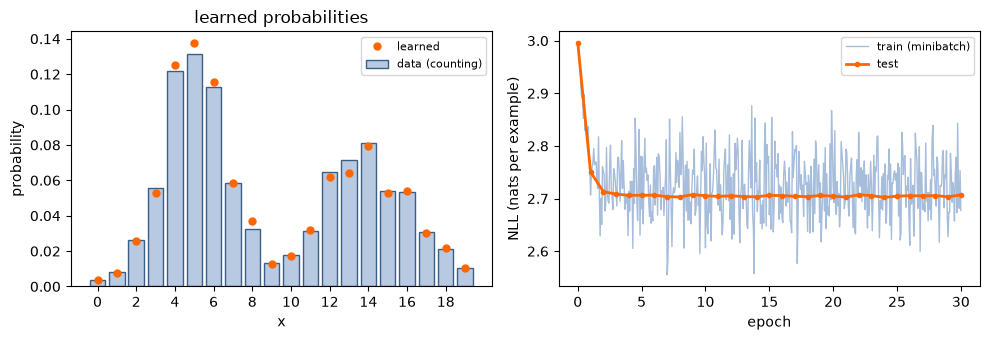

In [7]:
report("A1 categorical distribution", cat_test_losses, "nats per example")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
plot_categorical_fit(axes[0], x_train, d_1d, cat_probs, "learned probabilities")
plot_curves(axes[1], cat_train_losses, cat_test_losses, "NLL (nats per example)")
plt.tight_layout()
plt.show()

# B. Two variables

Two discrete variables $x_0, x_1 \in \{0, \dots, d-1\}$. All $d \times d$ pairs of values can be shown as a **heatmap**: the cell $(x_0, x_1)$ is coloured by the number of examples with this pair of values (bright = many, dark = few). $x_0$ is on the horizontal axis, $x_1$ on the vertical axis.

**A known example.** Take a 2D Gaussian with correlated variables, keep only the points inside the square $[-3, 3]^2$ and cut the square into $25 \times 25$ equal cells. The cell of a point gives the pair of integers $(x_0, x_1)$ in $\{0, \dots, 24\}$. Counting the points per cell gives the histogram, shown as a heatmap on the right.

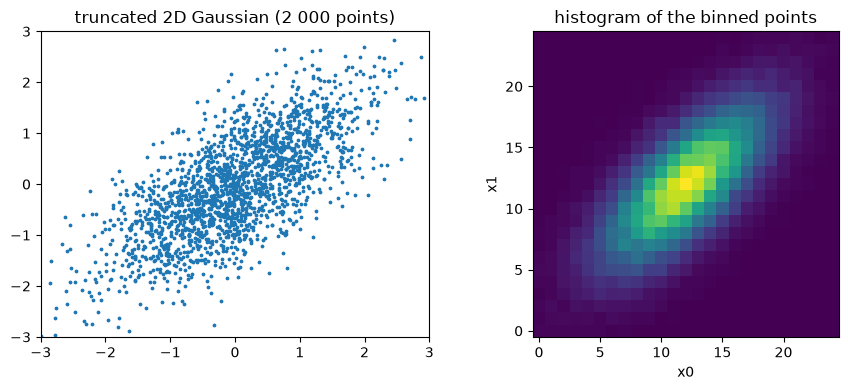

In [8]:
d_example = 25
x_gauss = sample_gaussian_2d(50000)
x_binned = torch.floor((x_gauss + 3.0) / 6.0 * d_example).long()  # integer cell index of every point

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].scatter(x_gauss[:2000, 0].numpy(), x_gauss[:2000, 1].numpy(), s=3)
axes[0].set_xlim(-3, 3)
axes[0].set_ylim(-3, 3)
axes[0].set_title("truncated 2D Gaussian (2 000 points)")
plot_table(axes[1], count_table(x_binned, d_example), "histogram of the binned points")
plt.tight_layout()
plt.show()

**Our data.** Two datasets of such integer pairs, with $d = 25$ (dataset 1: 50 000 training and 12 500 test points) and $d = 200$ (dataset 2: 200 000 and 50 000 points). The heatmaps below show their training data; they are not Gaussian.

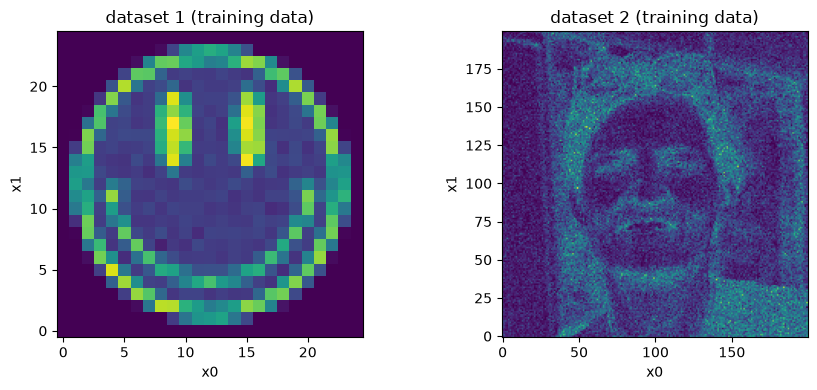

In [9]:
train1, test1, d1 = load_2d(1)
train2, test2, d2 = load_2d(2)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_table(axes[0], count_table(train1, d1), "dataset 1 (training data)")
plot_table(axes[1], count_table(train2, d2), "dataset 2 (training data)")
plt.tight_layout()
plt.show()

## B1. Independent model

The simplest model of two variables: they are **independent**, $p(x_0, x_1) = p(x_0)\,p(x_1)$. Every variable has its own categorical distribution over its $d$ values, as in A. Train it the same way, by gradient descent on the NLL.

**Task:** implement `independent_2d` in `lab02/tasks.py`. The function trains the model and returns the training and test losses and the $d \times d$ table of the joint probabilities $p(x_0, x_1)$ that the model assigns.

The first cell of each dataset runs your function (this is where the time goes). The second cell prints the final test NLL and plots, side by side, the training data, the learned probabilities (same colour scale convention: bright = high) and the loss curves: the training loss for every minibatch and the test loss after every epoch (the first point is the untrained model).

In [10]:
# dataset 1: train
ind_train1, ind_test1, ind_probs1 = independent_2d(train1, test1, d1, 1)

B1 independent, dataset 1: test NLL = 6.2145 nats per example


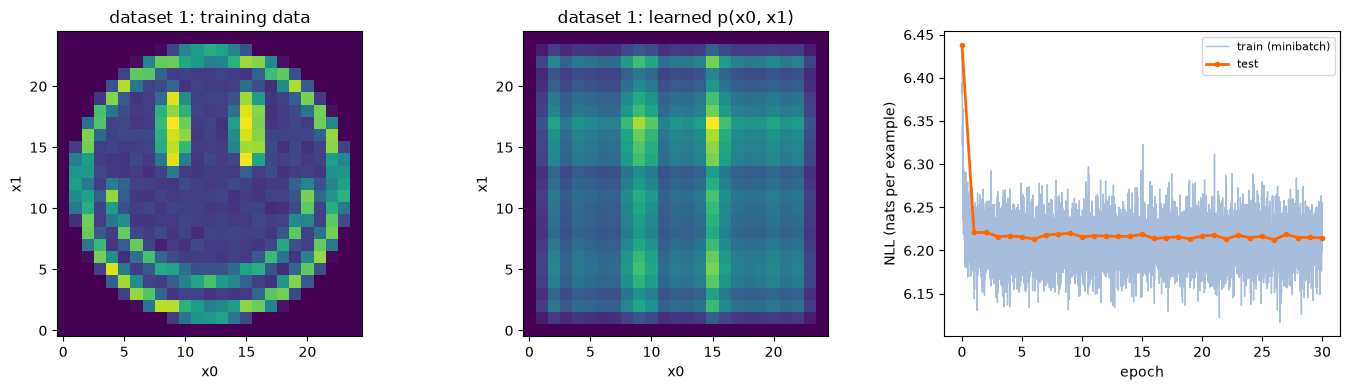

In [11]:
# dataset 1: results
report("B1 independent, dataset 1", ind_test1, "nats per example")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_2d_result(axes[:2], train1, ind_probs1, d1, "dataset 1")
plot_curves(axes[2], ind_train1, ind_test1, "NLL (nats per example)")
plt.tight_layout()
plt.show()

## B2. MADE

Now a model that can capture the dependence between $x_0$ and $x_1$: an autoregressive model of the form $p(x_0, x_1) = p(x_0)\,p(x_1 \mid x_0)$, computed by a single neural network - MADE (Germain et al., 2015, [arXiv:1502.03509](https://arxiv.org/abs/1502.03509)). Read the paper and implement the model yourself.

**Task:** implement `made_2d` in `lab02/tasks.py`. It has the same inputs and outputs as `independent_2d`. Training settings are yours, you may use different ones for the two datasets (`dset_id`).

**Suggested architecture:** one hidden layer with $4d$ units ($d$ = number of values of a variable); the width should be at least $d$. Two hidden layers work as well.

The cells work as above. Compare the test NLL and the learned probabilities with the independent model.

In [12]:
# dataset 1: train
made_train1, made_test1, made_probs1 = made_2d(train1, test1, d1, 1)

B2 MADE, dataset 1: test NLL = 5.8725 nats per example


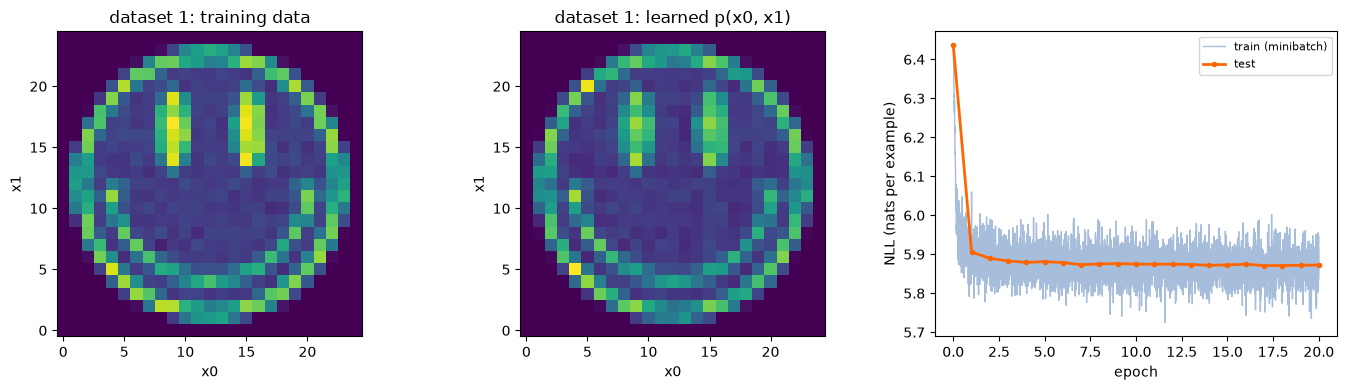

In [13]:
# dataset 1: results
report("B2 MADE, dataset 1", made_test1, "nats per example")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_2d_result(axes[:2], train1, made_probs1, d1, "dataset 1")
plot_curves(axes[2], made_train1, made_test1, "NLL (nats per example)")
plt.tight_layout()
plt.show()

In [14]:
# dataset 2: train
made_train2, made_test2, made_probs2 = made_2d(train2, test2, d2, 2)

B2 MADE, dataset 2: test NLL = 10.5738 nats per example


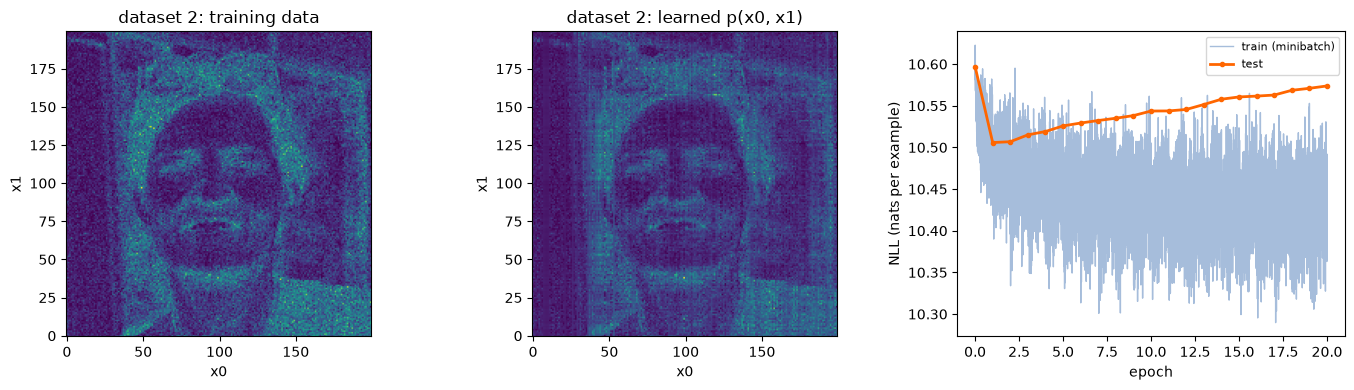

In [15]:
# dataset 2: results
report("B2 MADE, dataset 2", made_test2, "nats per example")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_2d_result(axes[:2], train2, made_probs2, d2, "dataset 2")
plot_curves(axes[2], made_train2, made_test2, "NLL (nats per example)")
plt.tight_layout()
plt.show()

# C. Images

The same idea for images. Every pixel is a variable with two values (ink or no ink) and the pixels are ordered row by row. An image of $H \times W$ pixels is then a sample of $D = HW$ dependent variables, so a table of probabilities is out of the question and the model must be a neural network.

- **Shapes**: $20 \times 20$ images of simple shapes (10 479 training, 4 491 test images)
- **MNIST**: $28 \times 28$ digits, thresholded as in Lab 1 (60 000 training, 10 000 test images)

In [16]:
shapes_train, shapes_test = load_shapes()
mnist_train, mnist_test = load_binary_mnist()

## C1. MADE on images

**Task:** implement `made_images` in `lab02/tasks.py`. It trains MADE on the given images and returns the training and test losses (here in **bits per pixel**) and 100 **new images sampled from the trained model**. Your code must work for any image size. Training settings are yours.

**Suggested architecture:** two hidden layers, 256 units each for Shapes and 512 units each for MNIST.

The first cell of each dataset runs your function, the second cell prints the final test NLL and shows the training images, the model's samples and the loss curves. A good model generates images that look like the training data.

In [20]:
# Shapes: train
shapes_train_losses, shapes_test_losses, shapes_samples = made_images(shapes_train, shapes_test)

Epoch 1/50 | Test BPP: 0.4043
Epoch 2/50 | Test BPP: 0.2728
Epoch 3/50 | Test BPP: 0.2213
Epoch 4/50 | Test BPP: 0.1939
Epoch 5/50 | Test BPP: 0.1736
Epoch 6/50 | Test BPP: 0.1567
Epoch 7/50 | Test BPP: 0.1435
Epoch 8/50 | Test BPP: 0.1332
Epoch 9/50 | Test BPP: 0.1259
Epoch 10/50 | Test BPP: 0.1197
Epoch 11/50 | Test BPP: 0.1150
Epoch 12/50 | Test BPP: 0.1108
Epoch 13/50 | Test BPP: 0.1072
Epoch 14/50 | Test BPP: 0.1040
Epoch 15/50 | Test BPP: 0.1012
Epoch 16/50 | Test BPP: 0.0988
Epoch 17/50 | Test BPP: 0.0967
Epoch 18/50 | Test BPP: 0.0948
Epoch 19/50 | Test BPP: 0.0927
Epoch 20/50 | Test BPP: 0.0910
Epoch 21/50 | Test BPP: 0.0893
Epoch 22/50 | Test BPP: 0.0880
Epoch 23/50 | Test BPP: 0.0869
Epoch 24/50 | Test BPP: 0.0857
Epoch 25/50 | Test BPP: 0.0848
Epoch 26/50 | Test BPP: 0.0840
Epoch 27/50 | Test BPP: 0.0831
Epoch 28/50 | Test BPP: 0.0824
Epoch 29/50 | Test BPP: 0.0816
Epoch 30/50 | Test BPP: 0.0811
Epoch 31/50 | Test BPP: 0.0805
Epoch 32/50 | Test BPP: 0.0800
Epoch 33/50 | Tes

C1 MADE, Shapes: test NLL = 0.0732 bits per pixel


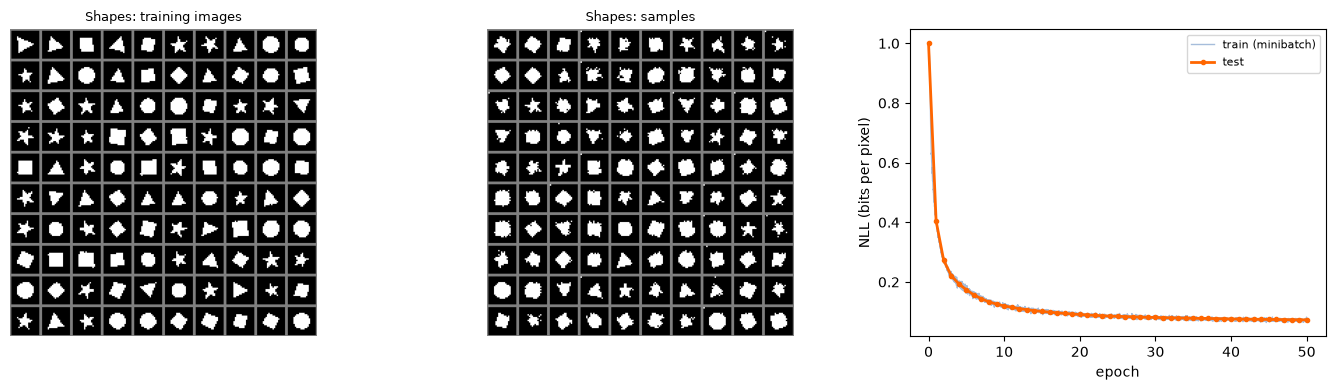

In [21]:
# Shapes: results
report("C1 MADE, Shapes", shapes_test_losses, "bits per pixel")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
show_images(axes[0], shapes_train, 10, 10, "Shapes: training images")
show_images(axes[1], shapes_samples, 10, 10, "Shapes: samples")
plot_curves(axes[2], shapes_train_losses, shapes_test_losses, "NLL (bits per pixel)")
plt.tight_layout()
plt.show()

In [22]:
# MNIST: train
mnist_train_losses, mnist_test_losses, mnist_samples = made_images(mnist_train, mnist_test)

Epoch 1/20 | Test BPP: 0.2808
Epoch 2/20 | Test BPP: 0.2256
Epoch 3/20 | Test BPP: 0.2041
Epoch 4/20 | Test BPP: 0.1919
Epoch 5/20 | Test BPP: 0.1847
Epoch 6/20 | Test BPP: 0.1798
Epoch 7/20 | Test BPP: 0.1757
Epoch 8/20 | Test BPP: 0.1728
Epoch 9/20 | Test BPP: 0.1705
Epoch 10/20 | Test BPP: 0.1685
Epoch 11/20 | Test BPP: 0.1670
Epoch 12/20 | Test BPP: 0.1656
Epoch 13/20 | Test BPP: 0.1642
Epoch 14/20 | Test BPP: 0.1634
Epoch 15/20 | Test BPP: 0.1632
Epoch 16/20 | Test BPP: 0.1621
Epoch 17/20 | Test BPP: 0.1616
Epoch 18/20 | Test BPP: 0.1607
Epoch 19/20 | Test BPP: 0.1602
Epoch 20/20 | Test BPP: 0.1597


C1 MADE, MNIST: test NLL = 0.1597 bits per pixel


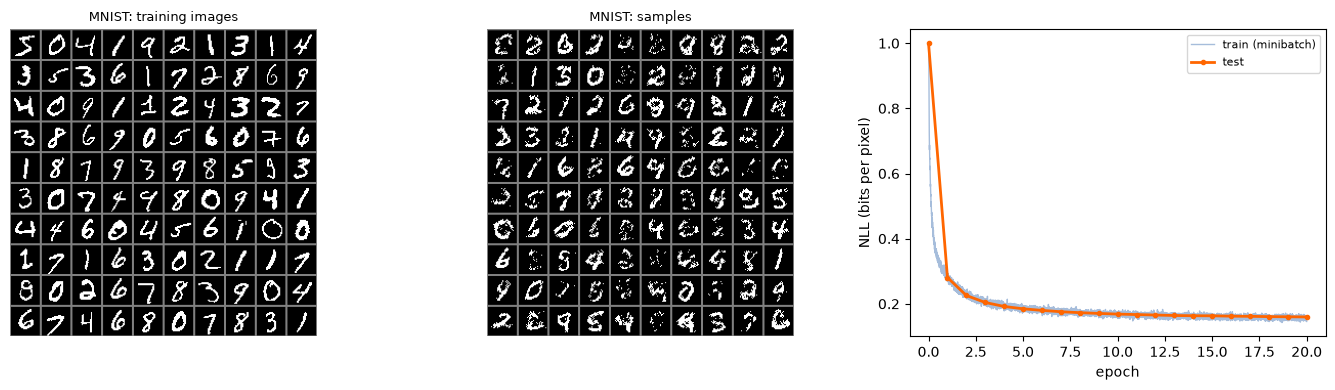

In [23]:
# MNIST: results
report("C1 MADE, MNIST", mnist_test_losses, "bits per pixel")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
show_images(axes[0], mnist_train, 10, 10, "MNIST: training images")
show_images(axes[1], mnist_samples, 10, 10, "MNIST: samples")
plot_curves(axes[2], mnist_train_losses, mnist_test_losses, "NLL (bits per pixel)")
plt.tight_layout()
plt.show()